In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("data/supermarket_sales.csv")

In [3]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:
df.shape

(1000, 17)

In [5]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='str')

In [6]:
df.dtypes

Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

In [12]:
df["Date"].dtype

dtype('<M8[us]')

In [13]:
df[["Date"]].head()

,Date
0,2019-01-05
1,2019-03-08
2,2019-03-03
3,2019-01-27
4,2019-02-08


In [15]:
round(df["Total"].sum(), 2)

np.float64(322966.75)

In [16]:
df["Total"].mean()

np.float64(322.966749)

In [17]:
df["Total"].max()

np.float64(1042.65)

In [19]:
df.loc[df["Total"].idxmax()]

Invoice ID                         860-79-0874
Branch                                       C
City                                 Naypyitaw
Customer type                           Member
Gender                                  Female
Product line               Fashion accessories
Unit price                                99.3
Quantity                                    10
Tax 5%                                   49.65
Total                                  1042.65
Date                       2019-02-15 00:00:00
Time                                     14:53
Payment                            Credit card
cogs                                     993.0
gross margin percentage               4.761905
gross income                             49.65
Rating                                     6.6
Name: 350, dtype: object

In [20]:
df["Total"].min()

np.float64(10.6785)

In [22]:
df.loc[df["Total"].idxmin()]

Invoice ID                         784-21-9238
Branch                                       C
City                                 Naypyitaw
Customer type                           Member
Gender                                    Male
Product line                 Sports and travel
Unit price                               10.17
Quantity                                     1
Tax 5%                                  0.5085
Total                                  10.6785
Date                       2019-02-07 00:00:00
Time                                     14:15
Payment                                   Cash
cogs                                     10.17
gross margin percentage               4.761905
gross income                            0.5085
Rating                                     5.9
Name: 822, dtype: object

In [24]:
df.groupby("Branch")["Total"].sum().sort_values(ascending=False)

Branch
C    110568.7065
A    106200.3705
B    106197.6720
Name: Total, dtype: float64

In [25]:
df.groupby("Product line")["Total"].sum().sort_values(ascending=False)

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64

In [27]:
df.groupby("Product line")["Quantity"].sum().sort_values(ascending=False)

Product line
Electronic accessories    971
Food and beverages        952
Sports and travel         920
Home and lifestyle        911
Fashion accessories       902
Health and beauty         854
Name: Quantity, dtype: int64

In [28]:
df.groupby("Product line").agg({
    "Total": "sum",
    "Quantity": "sum"
})

,Total,Quantity
Product line,,
Electronic accessories,54337.5315,971
Fashion accessories,54305.8950,902
Food and beverages,56144.8440,952
Health and beauty,49193.7390,854
Home and lifestyle,53861.9130,911
Sports and travel,55122.8265,920


In [31]:
category_sales = df.groupby("Product line").agg(
    Revenue=("Total", "sum"),
    Units_Sold=("Quantity", "sum")
).sort_values(by="Revenue", ascending=False)
category_sales

,Revenue,Units_Sold
Product line,,
Food and beverages,56144.8440,952
Sports and travel,55122.8265,920
Electronic accessories,54337.5315,971
Fashion accessories,54305.8950,902
Home and lifestyle,53861.9130,911
Health and beauty,49193.7390,854


In [32]:
import matplotlib.pyplot as plt

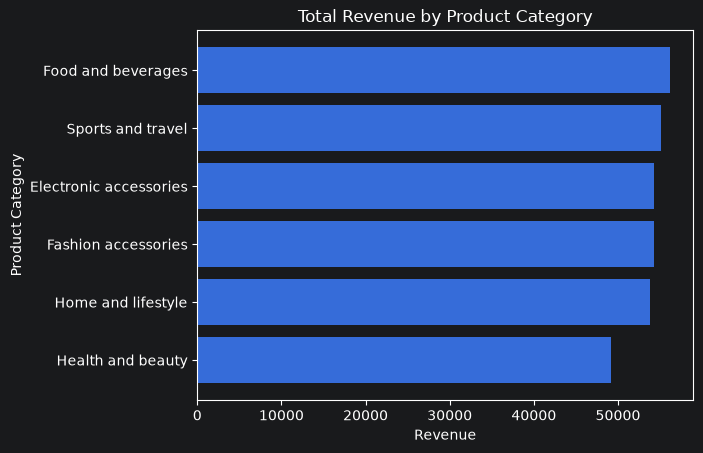

In [38]:
plt.barh(category_sales.index, category_sales["Revenue"])

plt.gca().invert_yaxis()

plt.title("Total Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.show()

In [39]:
plt.savefig("revenue_by_category.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [40]:
df["Month"] = df["Date"].dt.month

In [41]:
df[["Date", "Month"]].head()

,Date,Month
0,2019-01-05,1
1,2019-03-08,3
2,2019-03-03,3
3,2019-01-27,1
4,2019-02-08,2


In [46]:
monthly_sales = df.groupby("Month")["Total"].sum()
monthly_sales

Month
1    116291.868
2     97219.374
3    109455.507
Name: Total, dtype: float64

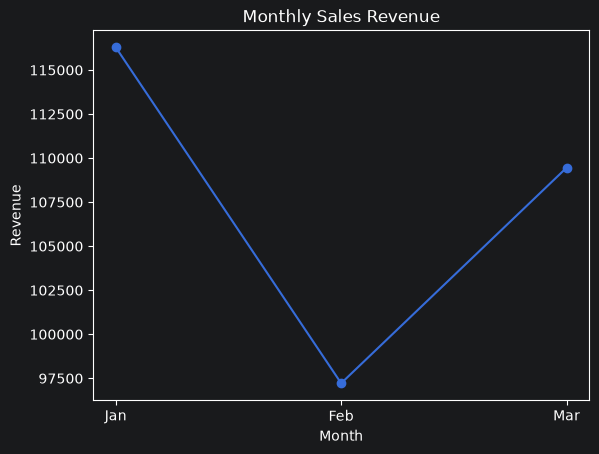

In [50]:
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(monthly_sales.index, ["Jan", "Feb", "Mar"])

plt.savefig("monthly_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

In [52]:
df["Payment"].value_counts(normalize=True) * 100

Payment
Ewallet        34.5
Cash           34.4
Credit card    31.1
Name: proportion, dtype: float64

In [53]:
df.groupby("Payment")["Total"].sum().sort_values(ascending=False)

Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Total, dtype: float64

In [54]:
df.groupby("Payment")["Total"].mean().sort_values(ascending=False)

Payment
Cash           326.181890
Credit card    324.009878
Ewallet        318.820600
Name: Total, dtype: float64

In [61]:
df.groupby("Customer type").agg(
    Total=("Total", "sum"),
    Average=("Total", "mean"),
    Transaction_Count=("Customer type", "count")
)


,Total,Average,Transaction_Count
Customer type,,,
Member,164223.444,327.791305,501
Normal,158743.305,318.122856,499


In [63]:
df["City"].unique()

<ArrowStringArray>
['Yangon', 'Naypyitaw', 'Mandalay']
Length: 3, dtype: str

In [66]:
city_sales = df.groupby("City").agg(
    Revenue=("Total", "sum"),
    Transactions=("Invoice ID", "count"),
    Average_Sale=("Total", "mean")
).sort_values(by="Revenue", ascending=False)
city_sales

,Revenue,Transactions,Average_Sale
City,,,
Naypyitaw,110568.7065,328,337.099715
Yangon,106200.3705,340,312.354031
Mandalay,106197.6720,332,319.872506


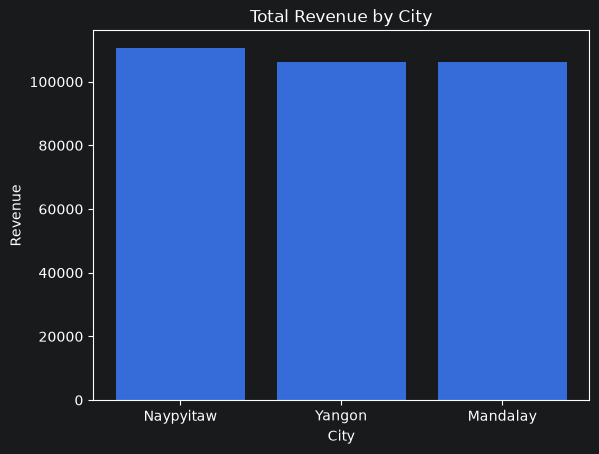

In [72]:
plt.bar(city_sales.index, city_sales["Revenue"])
plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")

plt.savefig("city_revenue.png", dpi=300, bbox_inches="tight")
plt.show()